# Entrega 2 (parte B) — Modelado
**Proyecto:** Predicción de cancelaciones de reservas hoteleras
**Curso:** Aprendizaje Máquina I — Maestría en Ciencia de Datos, Universidad Panamericana

Fase 4 de CRISP-DM:

1. **Selección del modelo:** tipo de problema, métricas y esquema de validación.
2. **Regresión logística desde cero** con NumPy (modelo más simple, para mostrar cómo funciona).
3. **Entrenamiento** y comparación de modelos con validación cruzada.
4. **Ajuste de hiperparámetros.**
5. Escenario con variables sospechosas de fuga (bitácora EDA #2).
6. Umbral de decisión, evaluación única en la prueba temporal e interpretación.
7. Empaquetado del modelo final para el servidor MCP.

## 0. Configuración y datos preparados

In [1]:
import inspect
import json
import time
import warnings
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import sklearn
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline

import hoteles
from hoteles.datos import Y, columnas_modelo
from hoteles.estilo import (AZUL, GRIS, MORADO, NARANJA, TINTA, TINTA2, VERDE, aplicar_estilo,
                            guardar, pct)
from hoteles.logistica_numpy import RegresionLogisticaNumpy
from hoteles.preprocesamiento import construir_preprocesador

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=sklearn.exceptions.UndefinedMetricWarning)
SEED = 42
RAIZ = Path("..").resolve()
PROC, FIG, TAB, MODELOS = (RAIZ / "data" / "processed", RAIZ / "report" / "figuras",
                           RAIZ / "report" / "tablas", RAIZ / "models")
MODELOS.mkdir(exist_ok=True)
aplicar_estilo()

train = pd.read_parquet(PROC / "train.parquet")
test = pd.read_parquet(PROC / "test.parquet")
X_tr, y_tr, g_tr = train.drop(columns=[Y]), train[Y].to_numpy(), train["grupo"].to_numpy()
X_te, y_te = test.drop(columns=[Y]), test[Y].to_numpy()
print(f"Entrenamiento: {X_tr.shape}, tasa {y_tr.mean():.3f} | Prueba: {X_te.shape}, tasa {y_te.mean():.3f}")

Entrenamiento: (97033, 43), tasa 0.363 | Prueba: (22177, 43), tasa 0.406


## 1. Selección del tipo de modelo, métricas y validación

- **Tipo de problema:** la variable objetivo `is_canceled` es binaria (0/1) y está etiquetada →
  **clasificación supervisada binaria**. No es regresión (no se predice una cantidad) ni
  *clustering* (sí hay etiqueta). Interesa además la **probabilidad** de cancelación, para
  priorizar reservas por riesgo (sobreventa controlada, recordatorios, depósitos).
- **Métrica principal: PR-AUC** (*average precision*). Con 37 % de positivos la exactitud de un
  clasificador trivial ya es 63 % (bitácora #10), y el área bajo la curva precisión-*recall* se
  centra en la clase que importa. Secundarias: ROC-AUC, F1, *recall* y precisión.
- **Validación:** `StratifiedGroupKFold` con 5 pliegues dentro del entrenamiento. Estratifica por
  la clase y mantiene cada grupo de filas duplicadas en un solo pliegue (bitácora #3), así que el
  modelo no puede "memorizar" una copia y evaluarse con su gemela.
- **Prueba:** el conjunto temporal (llegadas desde mayo de 2017) se usa una sola vez, al final.
- **Desbalance:** pesos de clase `balanced` en todos los modelos, sin sobremuestreo (bitácora #10).

In [2]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "recall": "recall",
            "precision": "precision"}


def pipeline(modelo, lineal, con_sospechosas=False):
    """Preprocesamiento (ajustado en cada pliegue) + modelo."""
    return Pipeline([("prep", construir_preprocesador(lineal, con_sospechosas)), ("modelo", modelo)])


def evaluar_cv(pipe, n_jobs=1):
    t0 = time.time()
    r = cross_validate(pipe, X_tr, y_tr, groups=g_tr, cv=CV, scoring=METRICAS, n_jobs=n_jobs)
    fila = {m: r[f"test_{m}"].mean() for m in METRICAS}
    fila["pr_auc_std"] = r["test_pr_auc"].std()
    fila["segundos"] = time.time() - t0
    return fila

## 2. Regresión logística implementada desde cero (solo NumPy)

El modelo más simple se programó sin librerías de aprendizaje automático
(`src/hoteles/logistica_numpy.py`) para mostrar qué ocurre dentro del `fit`.

**Modelo.** Para una reserva con variables $x \in \mathbb{R}^d$:
$$z = w^\top x + b, \qquad \hat p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
$\hat p$ es la probabilidad estimada de cancelación y $w$ indica cuánto sube o baja el
*log-odds* de cancelar por cada unidad (desviación estándar, tras escalar) de cada variable.

**Pérdida.** Entropía cruzada ponderada más penalización L2 (evita coeficientes enormes con 93
columnas, varias de ellas *one-hot* correlacionadas):
$$L(w,b) = -\frac{1}{\sum_i s_i}\sum_i s_i\left[y_i\log\hat p_i + (1-y_i)\log(1-\hat p_i)\right] + \frac{\lambda}{2}\lVert w\rVert^2$$
con $s_i = n / (2 n_{y_i})$ (pesos *balanced*: la clase minoritaria pesa más).

**Gradiente.** Como $\sigma'(z) = \sigma(z)(1-\sigma(z))$, la derivada se simplifica a una forma
muy compacta: el error de predicción multiplicado por la entrada:
$$\nabla_w L = \frac{1}{\sum_i s_i} X^\top\left[s \odot (\hat p - y)\right] + \lambda w, \qquad \frac{\partial L}{\partial b} = \frac{1}{\sum_i s_i}\sum_i s_i(\hat p_i - y_i)$$

**Optimización.** Descenso por gradiente con mini-lotes: en cada época se barajan las filas, se
recorren en lotes de 1,024 y se actualiza $w \leftarrow w - \eta \nabla_w L$. Se detiene cuando la
pérdida deja de bajar durante 5 épocas. Los hiperparámetros son la tasa de aprendizaje $\eta$ y
la fuerza de regularización $\lambda$.

El código del núcleo del algoritmo:

In [3]:
for metodo in (RegresionLogisticaNumpy.sigmoide, RegresionLogisticaNumpy.gradiente, RegresionLogisticaNumpy.fit):
    print(inspect.getsource(metodo))

    @staticmethod
    def sigmoide(z):
        """σ(z) numéricamente estable: evita exp de números grandes positivos o negativos."""
        z = np.asarray(z, dtype=float)
        out = np.empty_like(z)
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
        ez = np.exp(z[~pos])
        out[~pos] = ez / (1.0 + ez)
        return out

    def gradiente(self, X, y, s):
        """Gradiente analítico de la pérdida respecto a (w, b)."""
        p = self.sigmoide(X @ self.coef_ + self.intercept_)
        err = s * (p - y)
        norm = s.sum()
        return X.T @ err / norm + self.lambda_l2 * self.coef_, err.sum() / norm

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float).ravel()
        n, d = X.shape
        rng = np.random.default_rng(self.semilla)
        s = self._pesos_muestra(y)
        self.classes_ = np.array([0, 1])
        self.coef_ = np.zeros(d)
        self.intercept_ = 0.0
        self.historial_perdida_ = [self.perdida(

### 2.1 Verificación del gradiente

Antes de entrenar se comprueba que el gradiente analítico es correcto comparándolo con una
aproximación numérica por diferencias centrales,
$\partial L/\partial w_j \approx [L(w + \varepsilon e_j) - L(w - \varepsilon e_j)] / 2\varepsilon$.

In [4]:
prep_lin = construir_preprocesador(lineal=True).fit(X_tr)
Xm = prep_lin.transform(X_tr)
nombres = prep_lin[-1].get_feature_names_out()

rng = np.random.default_rng(SEED)
muestra = rng.choice(len(Xm), 3000, replace=False)
Xs, ys = Xm[muestra], y_tr[muestra].astype(float)
rl = RegresionLogisticaNumpy(lambda_l2=1e-3)
s = rl._pesos_muestra(ys)
rl.coef_, rl.intercept_ = rng.normal(0, 0.1, Xm.shape[1]), 0.1
g_w, g_b = rl.gradiente(Xs, ys, s)

eps, filas = 1e-6, []
for j in [0, 5, 20, 40, 80]:
    w0 = rl.coef_.copy()
    rl.coef_[j] += eps; mas = rl.perdida(Xs, ys, s)
    rl.coef_[j] -= 2 * eps; menos = rl.perdida(Xs, ys, s)
    rl.coef_ = w0
    filas.append((nombres[j], g_w[j], (mas - menos) / (2 * eps)))
chequeo = pd.DataFrame(filas, columns=["coeficiente", "gradiente analítico", "gradiente numérico"])
chequeo["error relativo"] = (chequeo.iloc[:, 1] - chequeo.iloc[:, 2]).abs() / chequeo.iloc[:, 2].abs()
chequeo

,coeficiente,gradiente analítico,gradiente numérico,error relativo
0,lead_time,-0.184244,-0.184244,3.343304e-10
1,days_in_waiting_list,-0.061026,-0.061026,2.499106e-10
2,tiene_ninos,-0.050509,-0.050509,1.890641e-10
3,distribution_channel_Corporate,0.007990,0.007990,1.857568e-08
4,company_Sin empresa,-0.001029,-0.001029,3.419603e-08


### 2.2 Entrenamiento y comparación con la implementación de scikit-learn

Se entrena con todo el conjunto de entrenamiento (ya transformado) y se compara contra
`sklearn.linear_model.LogisticRegression`, que optimiza la misma función con un método de
segundo orden (L-BFGS). Para que ambas minimicen la misma pérdida, $C = 1/(\lambda n)$.
scikit-learn se usa **solo como verificación**; el modelo del proyecto es la versión NumPy.

In [5]:
LAMBDA = 1e-4
t0 = time.time()
rl = RegresionLogisticaNumpy(lambda_l2=LAMBDA).fit(Xm, y_tr)
t_np = time.time() - t0
t0 = time.time()
sk = LogisticRegression(C=1 / (LAMBDA * len(Xm)), class_weight="balanced", max_iter=5000).fit(Xm, y_tr)
t_sk = time.time() - t0

p_np, p_sk = rl.predict_proba(Xm)[:, 1], sk.predict_proba(Xm)[:, 1]
pd.DataFrame({
    "NumPy (descenso por gradiente)": [rl.n_epocas_, t_np, rl.historial_perdida_[-1], roc_auc_score(y_tr, p_np), average_precision_score(y_tr, p_np)],
    "scikit-learn (L-BFGS)": [sk.n_iter_[0], t_sk, np.nan, roc_auc_score(y_tr, p_sk), average_precision_score(y_tr, p_sk)],
}, index=["épocas / iteraciones", "segundos", "pérdida final", "ROC-AUC (entrenamiento)", "PR-AUC (entrenamiento)"]).round(4)

,NumPy (descenso por gradiente),scikit-learn (L-BFGS)
épocas / iteraciones,46.0000,83.0000
segundos,3.1365,1.3056
pérdida final,0.4396,NaN
ROC-AUC (entrenamiento),0.8635,0.8659
PR-AUC (entrenamiento),0.8436,0.8455


Correlación de coeficientes: 0.9017; diferencia máxima de probabilidad: 0.3041


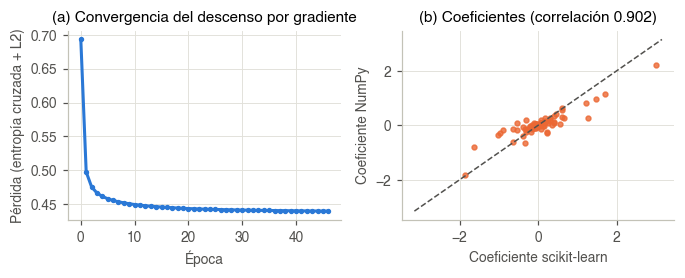

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6))
ax = axes[0]
ax.plot(range(len(rl.historial_perdida_)), rl.historial_perdida_, color=AZUL, lw=2, marker="o", ms=2.5)
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida (entropía cruzada + L2)")
ax.set_title("(a) Convergencia del descenso por gradiente")
ax = axes[1]
ax.scatter(sk.coef_[0], rl.coef_, s=10, color=NARANJA, alpha=0.8)
lim = np.abs(np.r_[sk.coef_[0], rl.coef_]).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color=TINTA2, lw=1, ls="--")
ax.set_xlabel("Coeficiente scikit-learn")
ax.set_ylabel("Coeficiente NumPy")
r = np.corrcoef(sk.coef_[0], rl.coef_)[0, 1]
ax.set_title(f"(b) Coeficientes (correlación {r:.3f})")
fig.tight_layout()
guardar(fig, FIG, "fig11_logistica_numpy")
print(f"Correlación de coeficientes: {r:.4f}; diferencia máxima de probabilidad: {np.abs(p_np - p_sk).max():.4f}")

**Lectura:** el gradiente analítico coincide con el numérico (error relativo < 1e-7), así que la
derivación es correcta. La implementación NumPy converge en 46 épocas y alcanza prácticamente el
mismo desempeño que scikit-learn en entrenamiento (ROC-AUC 0.864 vs 0.866; PR-AUC 0.844 vs 0.846).
Los coeficientes están muy correlacionados (0.90) pero no son idénticos, por dos razones:
(1) el descenso por gradiente con mini-lotes y tasa fija se detiene *cerca* del mínimo, mientras
L-BFGS lo alcanza con más precisión; y (2) el *one-hot* sin columna de referencia más el intercepto
crea direcciones redundantes (sumar una constante a todas las columnas de una variable y restarla
al intercepto no cambia la predicción), donde la penalización tan pequeña ($\lambda = 10^{-4}$)
apenas fija una solución. Por eso las probabilidades difieren en casos aislados (máx. 0.30) aunque
el ordenamiento de las reservas, que es lo que miden las AUC, es casi el mismo. NumPy tarda un poco
más (3 s vs 1.3 s), algo esperado frente a un optimizador de segundo orden en C.

## 3. Entrenamiento y comparación inicial (validación cruzada)

Se comparan, con hiperparámetros por defecto y en el escenario conservador:

- **Línea base:** predice la tasa de cancelación del entrenamiento para todos (PR-AUC = prevalencia).
- **Regresión logística (NumPy):** lineal, interpretable; necesita log + escalado.
- **Random Forest:** promedio de árboles profundos entrenados con *bootstrap*; captura no
  linealidades e interacciones (p. ej., depósito × segmento).
- **Gradient Boosting (HistGradientBoosting):** árboles secuenciales que corrigen el error del
  anterior; suele ser el más preciso en datos tabulares.

In [7]:
candidatos = {
    "Línea base (prevalencia)": (pipeline(DummyClassifier(strategy="prior"), lineal=False), 1),
    "Regresión logística (NumPy)": (pipeline(RegresionLogisticaNumpy(), lineal=True), 5),
    "Random Forest": (pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
                                                      n_jobs=-1, random_state=SEED), lineal=False), 1),
    "Gradient Boosting (HGB)": (pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED), lineal=False), 1),
}
inicial = pd.DataFrame({n: evaluar_cv(p, n_jobs=j) for n, (p, j) in candidatos.items()}).T
inicial.round(3)

,pr_auc,roc_auc,f1,recall,precision,pr_auc_std,segundos
Línea base (prevalencia),0.363,0.500,0.000,0.000,0.000,0.011,11.120
Regresión logística (NumPy),0.842,0.861,0.725,0.714,0.737,0.010,13.524
Random Forest,0.872,0.895,0.764,0.708,0.829,0.010,25.158
Gradient Boosting (HGB),0.867,0.891,0.756,0.728,0.787,0.010,30.535


**Lectura:** los tres modelos superan con holgura a la línea base (PR-AUC 0.36). Con parámetros
por defecto, los modelos de árboles (Random Forest 0.872, *Gradient Boosting* 0.867) superan a la
logística (0.842) por unos 3 puntos de PR-AUC, como anticipaba el EDA (§9: señal repartida y no
lineal, interacciones como depósito × segmento). La desviación estándar entre pliegues (≈ 0.01)
indica que las diferencias entre árboles y logística son mayores que el ruido de la validación,
pero entre RF y HGB no.

## 4. Ajuste de hiperparámetros

Toda búsqueda usa la misma validación cruzada agrupada y optimiza PR-AUC. El preprocesamiento
está dentro del Pipeline, así que se reajusta en cada pliegue (sin fuga).

| Modelo | Búsqueda | Hiperparámetros |
|---|---|---|
| Logística NumPy | Rejilla completa (12 combinaciones × 5 pliegues) | tasa de aprendizaje $\eta$, regularización $\lambda$ |
| Gradient Boosting | Aleatoria (20 combinaciones × 5 pliegues) | tasa de aprendizaje, hojas por árbol, mínimo de muestras por hoja, L2, fracción de variables (con parada temprana) |
| Random Forest | Aleatoria (6 combinaciones × 5 pliegues; es el más costoso) | número de árboles, profundidad, mínimo por hoja, variables por división |

In [8]:
t0 = time.time()
busq_lr = GridSearchCV(pipeline(RegresionLogisticaNumpy(), lineal=True),
                       {"modelo__tasa_aprendizaje": [0.03, 0.1, 0.3],
                        "modelo__lambda_l2": [1e-5, 1e-4, 1e-3, 1e-2]},
                       scoring=METRICAS, refit="pr_auc", cv=CV, n_jobs=5).fit(X_tr, y_tr, groups=g_tr)
print(f"Logística NumPy: {time.time() - t0:.0f} s, mejor PR-AUC {busq_lr.best_score_:.4f}, {busq_lr.best_params_}")

Logística NumPy: 38 s, mejor PR-AUC 0.8423, {'modelo__lambda_l2': 1e-05, 'modelo__tasa_aprendizaje': 0.3}


In [9]:
t0 = time.time()
hgb = HistGradientBoostingClassifier(class_weight="balanced", max_iter=600, early_stopping=True,
                                     n_iter_no_change=20, random_state=SEED)
busq_hgb = RandomizedSearchCV(pipeline(hgb, lineal=False),
                              {"modelo__learning_rate": loguniform(0.02, 0.3),
                               "modelo__max_leaf_nodes": randint(15, 128),
                               "modelo__min_samples_leaf": randint(10, 200),
                               "modelo__l2_regularization": loguniform(1e-3, 10),
                               "modelo__max_features": uniform(0.3, 0.7)},
                              n_iter=20, scoring=METRICAS, refit="pr_auc", cv=CV, n_jobs=1,
                              random_state=SEED).fit(X_tr, y_tr, groups=g_tr)
print(f"HGB: {time.time() - t0:.0f} s, mejor PR-AUC {busq_hgb.best_score_:.4f}")
busq_hgb.best_params_

HGB: 1240 s, mejor PR-AUC 0.8726


{'modelo__l2_regularization': 0.004207988669606638,
 'modelo__learning_rate': 0.03051362379613698,
 'modelo__max_features': 0.3406585285177396,
 'modelo__max_leaf_nodes': 102,
 'modelo__min_samples_leaf': 126}

In [10]:
t0 = time.time()
rf = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
busq_rf = RandomizedSearchCV(pipeline(rf, lineal=False),
                             {"modelo__n_estimators": [150, 250],
                              "modelo__max_depth": [None, 20, 30],
                              "modelo__min_samples_leaf": [1, 2, 5, 10],
                              "modelo__max_features": ["sqrt", 0.25, 0.4]},
                             n_iter=6, scoring=METRICAS, refit="pr_auc", cv=CV, n_jobs=1,
                             random_state=SEED).fit(X_tr, y_tr, groups=g_tr)
print(f"Random Forest: {time.time() - t0:.0f} s, mejor PR-AUC {busq_rf.best_score_:.4f}")
busq_rf.best_params_

Random Forest: 98 s, mejor PR-AUC 0.8724


{'modelo__n_estimators': 150,
 'modelo__min_samples_leaf': 2,
 'modelo__max_features': 'sqrt',
 'modelo__max_depth': 30}

In [11]:
ajustados = {"Regresión logística (NumPy)": busq_lr, "Random Forest": busq_rf, "Gradient Boosting (HGB)": busq_hgb}
filas = []
for nombre, b in ajustados.items():
    res = b.cv_results_
    i = b.best_index_
    fila = {"modelo": nombre, "PR-AUC por defecto": inicial.loc[nombre, "pr_auc"]}
    fila.update({m: res[f"mean_test_{m}"][i] for m in METRICAS})
    fila["pr_auc_std"] = res["std_test_pr_auc"][i]
    fila["mejores hiperparámetros"] = ", ".join(f"{k.replace('modelo__', '')}={v:.3g}" if isinstance(v, float) else f"{k.replace('modelo__', '')}={v}"
                                                for k, v in b.best_params_.items())
    filas.append(fila)
tuneo = pd.DataFrame(filas).set_index("modelo")
with open(TAB / "modelos_cv.tex", "w") as f:
    f.write(f"Línea base (prevalencia) & -- & {inicial.loc['Línea base (prevalencia)', 'pr_auc']:.3f} & {inicial.loc['Línea base (prevalencia)', 'roc_auc']:.3f} & -- & -- & -- \\\\\n")
    for n, r in tuneo.iterrows():
        f.write(f"{n} & {r['PR-AUC por defecto']:.3f} & {r['pr_auc']:.3f} $\\pm$ {r['pr_auc_std']:.3f} & {r['roc_auc']:.3f} & "
                f"{r['f1']:.3f} & {r['recall']:.3f} & {r['precision']:.3f} \\\\\n")
with open(TAB / "hiperparametros.tex", "w") as f:
    for n, r in tuneo.iterrows():
        f.write(f"{n} & \\texttt{{{r['mejores hiperparámetros'].replace('_', chr(92) + '_')}}} \\\\\n")
tuneo.round(4)

,PR-AUC por defecto,pr_auc,roc_auc,f1,recall,precision,pr_auc_std,mejores hiperparámetros
modelo,,,,,,,,
Regresión logística (NumPy),0.8418,0.8423,0.8624,0.7270,0.7193,0.7353,0.0103,"lambda_l2=1e-05, tasa_aprendizaje=0.3"
Random Forest,0.8725,0.8724,0.8958,0.7638,0.7115,0.8245,0.0099,"n_estimators=150, min_samples_leaf=2, max_feat..."
Gradient Boosting (HGB),0.8667,0.8726,0.8964,0.7643,0.7457,0.7839,0.0103,"l2_regularization=0.00421, learning_rate=0.030..."


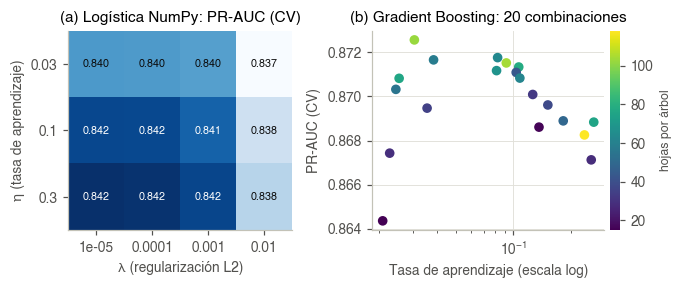

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.7), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
res = pd.DataFrame(busq_lr.cv_results_)
mapa = res.pivot_table(index="param_modelo__tasa_aprendizaje", columns="param_modelo__lambda_l2", values="mean_test_pr_auc")
im = ax.imshow(mapa.values, cmap="Blues", aspect="auto")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7,
                color="white" if v > np.nanmean(mapa.values) else TINTA)
ax.set_xticks(range(mapa.shape[1]), [f"{c:g}" for c in mapa.columns])
ax.set_yticks(range(mapa.shape[0]), [f"{c:g}" for c in mapa.index])
ax.set_xlabel("λ (regularización L2)")
ax.set_ylabel("η (tasa de aprendizaje)")
ax.set_title("(a) Logística NumPy: PR-AUC (CV)")
ax.grid(False)
ax = axes[1]
res = pd.DataFrame(busq_hgb.cv_results_)
sc = ax.scatter(res["param_modelo__learning_rate"].astype(float), res["mean_test_pr_auc"],
                c=res["param_modelo__max_leaf_nodes"].astype(float), cmap="viridis", s=28)
ax.set_xscale("log")
ax.set_xlabel("Tasa de aprendizaje (escala log)")
ax.set_ylabel("PR-AUC (CV)")
ax.set_title("(b) Gradient Boosting: 20 combinaciones")
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("hojas por árbol", fontsize=8)
cb.outline.set_visible(False)
fig.tight_layout()
guardar(fig, FIG, "fig12_hiperparametros")

In [13]:
# Interpretación de la logística NumPy ajustada: coeficientes sobre variables estandarizadas.
lr_final = busq_lr.best_estimator_
coefs = pd.Series(lr_final["modelo"].coef_, index=lr_final["prep"][-1].get_feature_names_out())
pd.concat([coefs.nlargest(8).rename("aumenta el riesgo"), coefs.nsmallest(8).rename("reduce el riesgo")], axis=1).round(2)

,aumenta el riesgo,reduce el riesgo
deposit_type_Non Refund,2.70,NaN
agent_A240,1.38,NaN
tasa_cancelacion_previa,1.18,NaN
agent_A9,0.96,NaN
agent_A242,0.66,NaN
lead_time,0.61,NaN
customer_type_Transient,0.60,NaN
distribution_channel_Corporate,0.52,NaN
deposit_type_No Deposit,NaN,-2.04
agent_A28,NaN,-1.24


**Lectura:**

- **Logística NumPy:** la mejor combinación es la tasa de aprendizaje más alta (η = 0.3) con la
  regularización más débil (λ = 1e-5). Una λ de 1e-2 reduce el PR-AUC de forma visible (mapa a):
  con 97 mil filas y 93 columnas el modelo está lejos del sobreajuste y lo que le falta es
  capacidad (no puede representar no linealidades). La ganancia del ajuste es marginal (0.842 →
  0.842).
- **Gradient Boosting:** es el que más gana con el ajuste (0.867 → 0.873): prefiere tasas de
  aprendizaje bajas (≈ 0.03), árboles grandes (≈ 100 hojas) con hojas de al menos ≈ 125 reservas y
  solo un tercio de las variables por división (más regularización por aleatoriedad).
- **Random Forest:** su configuración por defecto ya era casi óptima (0.8725 → 0.8724).
- HGB y RF empatan en validación (0.8726 vs 0.8724, diferencia muy inferior a la desviación de
  0.01). Se elige **HGB** como modelo final por mayor ROC-AUC y *recall*, y porque el artefacto es
  mucho más ligero para el servidor (3 MB vs cientos de MB de un bosque profundo).
- **Coeficientes de la logística** (variables estandarizadas): `deposit_type = Non Refund` es el
  mayor factor de riesgo, seguido de algunas agencias específicas (240, 9), la tasa de cancelación
  previa y la anticipación. Reducen el riesgo: `No Deposit` frente a `Non Refund`, ciertas agencias
  y empresas, y las solicitudes especiales (un cliente que pide algo planea llegar).

## 5. Escenario con variables sospechosas de fuga

Bitácora #2: `country`, `required_car_parking_spaces` y `booking_changes` podrían registrarse
después de hacer la reserva (al llegar el huésped). Se vuelve a evaluar el mejor modelo de árboles,
con los mismos hiperparámetros, agregándolas. Si la métrica sube mucho, es una señal de que
dependen del desenlace y no estarían disponibles al momento de predecir.

In [14]:
mejor_arbol = "Gradient Boosting (HGB)" if busq_hgb.best_score_ >= busq_rf.best_score_ else "Random Forest"
pipe_cons = ajustados[mejor_arbol].best_estimator_
pipe_sosp = clone(pipe_cons).set_params(prep=construir_preprocesador(lineal=False, con_sospechosas=True))
escenarios = pd.DataFrame({
    "Conservador (sin sospechosas)": tuneo.loc[mejor_arbol, list(METRICAS)],
    "Completo (con sospechosas)": pd.Series(evaluar_cv(pipe_sosp))[list(METRICAS)],
}).T.astype(float)
escenarios.loc["Diferencia"] = escenarios.iloc[1] - escenarios.iloc[0]
print("Modelo:", mejor_arbol)
escenarios.round(4)

Modelo: Gradient Boosting (HGB)


,pr_auc,roc_auc,f1,recall,precision
Conservador (sin sospechosas),0.8726,0.8964,0.7643,0.7457,0.7839
Completo (con sospechosas),0.9265,0.9509,0.8312,0.8532,0.8103
Diferencia,0.0539,0.0545,0.0669,0.1075,0.0264


**Lectura:** agregar `country`, `required_car_parking_spaces` y `booking_changes` sube el PR-AUC
de 0.873 a 0.927 (+5.4 puntos) y el *recall* en 10.8 puntos. Es una mejora demasiado grande para
tres variables, coherente con la sospecha del EDA: el estacionamiento separa perfectamente (nadie
que lo pidió canceló) porque probablemente se registra al llegar, y el país se corrige en el
*check-in*. Ese desempeño **no estaría disponible en operación**, porque al predecir (al momento de
la reserva) esos valores todavía no existen o no son definitivos. El modelo final se queda en el
escenario **conservador**; el completo se reporta solo como cota superior.

## 6. Modelo final y umbral de decisión

Se elige el modelo con mayor PR-AUC en validación cruzada (no en prueba). La probabilidad se
convierte en decisión con un umbral; en lugar de usar 0.5 por omisión, se elige el umbral que
maximiza F1 sobre las **predicciones fuera de pliegue** del entrenamiento (cada reserva es
predicha por un modelo que no la vio), de nuevo sin tocar la prueba.

In [15]:
mejor_nombre = tuneo["pr_auc"].idxmax()
final = ajustados[mejor_nombre].best_estimator_
oof = cross_val_predict(clone(final), X_tr, y_tr, groups=g_tr, cv=CV, method="predict_proba")[:, 1]
prec, rec, umbrales = precision_recall_curve(y_tr, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
k = int(np.argmax(f1s))
UMBRAL = float(umbrales[k])
print(f"Modelo final: {mejor_nombre}")
print(f"Umbral F1-óptimo (fuera de pliegue): {UMBRAL:.3f} -> precisión {prec[k]:.3f}, recall {rec[k]:.3f}, F1 {f1s[k]:.3f}")
print(f"Con umbral 0.5: F1 {f1_score(y_tr, oof >= 0.5):.3f}")

Modelo final: Gradient Boosting (HGB)
Umbral F1-óptimo (fuera de pliegue): 0.551 -> precisión 0.815, recall 0.722, F1 0.766
Con umbral 0.5: F1 0.765


## 7. Evaluación final en la prueba temporal

Primera y única vez que se usan las llegadas de mayo a agosto de 2017. Se reportan todos los
modelos ajustados (para la discusión) y el escenario con sospechosas, pero la selección ya se hizo
arriba con validación cruzada.

In [16]:
def metricas_prueba(p, umbral):
    pred = (p >= umbral).astype(int)
    return {"pr_auc": average_precision_score(y_te, p), "roc_auc": roc_auc_score(y_te, p),
            "f1": f1_score(y_te, pred), "recall": recall_score(y_te, pred),
            "precision": precision_score(y_te, pred), "exactitud": accuracy_score(y_te, pred)}


probs = {n: b.best_estimator_.predict_proba(X_te)[:, 1] for n, b in ajustados.items()}
probs[f"{mejor_arbol} con sospechosas"] = pipe_sosp.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
prueba = pd.DataFrame({n: metricas_prueba(p, UMBRAL if n == mejor_nombre else 0.5) for n, p in probs.items()}).T
prueba.loc["Línea base (prevalencia)"] = [y_te.mean(), 0.5, np.nan, np.nan, np.nan, 1 - y_te.mean()]
with open(TAB / "prueba.tex", "w") as f:
    for n, r in prueba.iterrows():
        f.write(f"{n} & " + " & ".join("--" if pd.isna(v) else f"{v:.3f}" for v in r.values) + " \\\\\n")
prueba.round(3)

,pr_auc,roc_auc,f1,recall,precision,exactitud
Regresión logística (NumPy),0.785,0.811,0.679,0.671,0.687,0.743
Random Forest,0.786,0.820,0.630,0.527,0.783,0.749
Gradient Boosting (HGB),0.791,0.824,0.645,0.556,0.767,0.751
Gradient Boosting (HGB) con sospechosas,0.837,0.877,0.723,0.667,0.789,0.792
Línea base (prevalencia),0.406,0.500,NaN,NaN,NaN,0.594


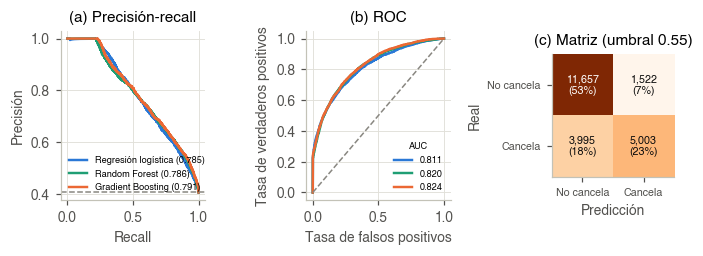

In [17]:
p_final = probs[mejor_nombre]
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.4), gridspec_kw={"width_ratios": [1, 1, 0.85]})
colores = {"Regresión logística (NumPy)": AZUL, "Random Forest": VERDE, "Gradient Boosting (HGB)": NARANJA}
for n, c in colores.items():
    pr, rc, _ = precision_recall_curve(y_te, probs[n])
    axes[0].plot(rc, pr, color=c, lw=1.6, label=f"{n.split(' (')[0]} ({average_precision_score(y_te, probs[n]):.3f})")
    fpr, tpr, _ = roc_curve(y_te, probs[n])
    axes[1].plot(fpr, tpr, color=c, lw=1.6, label=f"{roc_auc_score(y_te, probs[n]):.3f}")
axes[0].axhline(y_te.mean(), color=GRIS, ls="--", lw=1)
axes[0].set(xlabel="Recall", ylabel="Precisión", title="(a) Precisión-recall")
axes[0].legend(fontsize=6, loc="lower left")
axes[1].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
axes[1].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="(b) ROC")
axes[1].legend(fontsize=6, loc="lower right", title="AUC", title_fontsize=6)
cm = confusion_matrix(y_te, p_final >= UMBRAL)
ax = axes[2]
ax.imshow(cm, cmap="Oranges")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.0%})", ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else TINTA)
ax.set_xticks([0, 1], ["No cancela", "Cancela"], fontsize=7)
ax.set_yticks([0, 1], ["No cancela", "Cancela"], fontsize=7)
ax.set(xlabel="Predicción", ylabel="Real", title=f"(c) Matriz (umbral {UMBRAL:.2f})")
ax.grid(False)
fig.tight_layout()
guardar(fig, FIG, "fig13_prueba")

In [18]:
# Desempeño por hotel (bitácora EDA §4: las tasas difieren mucho entre hoteles).
filas = []
for h in ["City Hotel", "Resort Hotel"]:
    m = (test["hotel"] == h).to_numpy()
    pred = p_final[m] >= UMBRAL
    filas.append({"hotel": h, "reservas": m.sum(), "tasa real": y_te[m].mean(), "tasa predicha": pred.mean(),
                  "pr_auc": average_precision_score(y_te[m], p_final[m]), "roc_auc": roc_auc_score(y_te[m], p_final[m]),
                  "recall": recall_score(y_te[m], pred), "precision": precision_score(y_te[m], pred)})
por_hotel = pd.DataFrame(filas).set_index("hotel")
por_hotel.round(3)

,reservas,tasa real,tasa predicha,pr_auc,roc_auc,recall,precision
hotel,,,,,,,
City Hotel,15191,0.426,0.339,0.817,0.830,0.612,0.769
Resort Hotel,6986,0.362,0.198,0.732,0.812,0.413,0.757


In [19]:
# Traducción a los KPIs del negocio (Entrega 1, §2): ingreso en riesgo = ADR x noches.
ingreso = test["adr"].clip(lower=0) * test["noches"]
pred = p_final >= UMBRAL
cancel = y_te == 1
negocio = pd.Series({
    "Cancelaciones reales en prueba": int(cancel.sum()),
    "Cancelaciones anticipadas por el modelo": int((pred & cancel).sum()),
    "Falsas alarmas (no cancelaron)": int((pred & ~cancel).sum()),
    "Ingreso en riesgo total (millones)": ingreso[cancel].sum() / 1e6,
    "Ingreso en riesgo anticipado (millones)": ingreso[pred & cancel].sum() / 1e6,
    "% del ingreso en riesgo anticipado": ingreso[pred & cancel].sum() / ingreso[cancel].sum(),
    "Habitaciones-noche canceladas anticipadas": int(test.loc[pred & cancel, "noches"].sum()),
})
negocio.round(3)

Cancelaciones reales en prueba                8998.000
Cancelaciones anticipadas por el modelo       5003.000
Falsas alarmas (no cancelaron)                1522.000
Ingreso en riesgo total (millones)               4.987
Ingreso en riesgo anticipado (millones)          2.688
% del ingreso en riesgo anticipado               0.539
Habitaciones-noche canceladas anticipadas    18890.000
dtype: float64

,media,std
deposit_type,0.2249,0.0063
total_of_special_requests,0.0729,0.0028
lead_time,0.0388,0.0034
agent,0.0363,0.0031
customer_type,0.0325,0.0013
market_segment,0.0248,0.0012
adr_por_persona,0.0052,0.0008
adr,0.0035,0.0005
previous_bookings_not_canceled,0.0030,0.0013
dia_semana,0.0026,0.0004


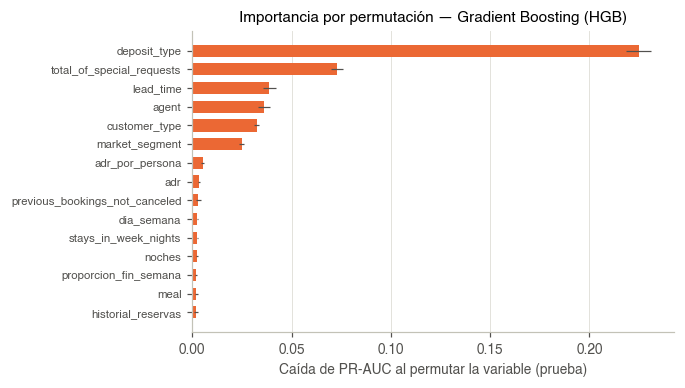

In [20]:
num, cat = columnas_modelo(False)
idx = np.random.default_rng(SEED).choice(len(X_te), 6000, replace=False)
imp = permutation_importance(final, X_te.iloc[idx][num + cat], y_te[idx], scoring="average_precision",
                             n_repeats=5, random_state=SEED, n_jobs=1)
importancia = pd.DataFrame({"media": imp.importances_mean, "std": imp.importances_std}, index=num + cat).sort_values("media")
top = importancia.tail(15)
fig, ax = plt.subplots(figsize=(6.3, 3.6))
ax.barh(top.index, top["media"], xerr=top["std"], color=NARANJA, height=0.65, error_kw={"lw": 0.8, "ecolor": TINTA2})
ax.set_xlabel("Caída de PR-AUC al permutar la variable (prueba)")
ax.set_title(f"Importancia por permutación — {mejor_nombre}")
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, FIG, "fig14_importancia")
importancia.sort_values("media", ascending=False).head(10).round(4)

**Lectura de la prueba temporal (may–ago 2017):**

- **Desempeño:** el modelo final (HGB) obtiene PR-AUC 0.791 y ROC-AUC 0.824 en prueba, frente a
  0.873 / 0.896 en validación cruzada. La caída se explica por la **deriva temporal** documentada en
  la preparación: la tasa de cancelación del resort pasa de 26 % en entrenamiento a 36 % en prueba.
  El modelo ordena bien las reservas por riesgo (las AUC siguen siendo altas), pero las
  probabilidades quedan desplazadas a la baja: predice cancelación en 30 % de las reservas cuando
  en realidad cancela el 41 %. Por eso el *recall* cae a 0.56 con el umbral elegido (0.55), con una
  precisión alta (0.77).
- **Por hotel:** el efecto es mucho mayor en el resort (*recall* 0.41) que en el urbano (0.61).
- **Comparación:** en prueba los tres modelos quedan muy cerca en PR-AUC (0.785–0.791). La
  logística NumPy, menos flexible, se ve menos afectada por el cambio de distribución y tiene el
  mejor F1 con umbral 0.5 (0.68), aunque menor precisión. La lección es que, ante deriva, el
  **umbral** (y la calibración) debe revisarse periódicamente con datos recientes; el modelo de
  árboles conserva la mejor capacidad de ordenar.
- **Fuga:** el escenario con sospechosas también "gana" en prueba (0.837), pero por la misma razón
  que en validación: usa información que no existe al reservar.
- **Negocio:** con el umbral elegido el modelo anticipa 5,003 de 8,998 cancelaciones (56 %) con
  1,522 falsas alarmas, lo que equivale a **2.69 de los 4.99 millones (54 %) de ingreso en riesgo**
  y 18,890 habitaciones-noche identificadas con anticipación.
- **Importancia:** `deposit_type` domina (al permutarlo el PR-AUC cae 0.22), seguido de
  `total_of_special_requests`, `lead_time`, `agent`, `customer_type` y `market_segment`, lo que
  coincide con el EDA (§7 y §9.2). Las variables de calendario y precio aportan poco.

## 8. Empaquetado del modelo final

Se guarda un único artefacto con el Pipeline completo (limpieza aprendida + modelo), el umbral y
metadatos. El servidor MCP (`mcp_server/server.py`) lo carga con `hoteles.prediccion`, que aplica
las mismas funciones de limpieza e ingeniería de características que este proyecto.

In [21]:
metadatos = {
    "proyecto": "Predicción de cancelaciones de reservas hoteleras",
    "version_paquete": hoteles.__version__,
    "modelo": mejor_nombre,
    "escenario": "conservador (sin country, required_car_parking_spaces ni booking_changes)",
    "fecha_entrenamiento": str(date.today()),
    "datos": "Hotel Booking Demand (Antonio et al., 2019); entrenamiento: llegadas jul-2015 a abr-2017",
    "hiperparametros": {k.replace("modelo__", ""): (float(v) if isinstance(v, (float, np.floating)) else v)
                        for k, v in ajustados[mejor_nombre].best_params_.items()},
    "umbral": UMBRAL,
    "metricas_cv": {m: float(tuneo.loc[mejor_nombre, m]) for m in METRICAS},
    "metricas_prueba": {m: float(v) for m, v in prueba.loc[mejor_nombre].items()},
    "variables_entrada": {"numericas": num, "categoricas": cat},
    "versiones": {"python": __import__("platform").python_version(), "scikit-learn": sklearn.__version__,
                  "numpy": np.__version__, "pandas": pd.__version__},
    "limitaciones": [
        "Entrenado con dos hoteles de Portugal (2015-2017); fuera de ese contexto requiere reentrenar.",
        "La tasa de cancelación tiene deriva temporal: conviene reentrenar periódicamente.",
        "deposit_type = Non Refund se asocia a cancelación por bloques de agencias/grupos, no es causal.",
    ],
}
joblib.dump({"modelo": final, "umbral": UMBRAL, "metadatos": metadatos}, MODELOS / "modelo_final.joblib", compress=3)
(MODELOS / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2))
print(f"{(MODELOS / 'modelo_final.joblib').stat().st_size / 1e6:.2f} MB")

2.97 MB


In [22]:
# Prueba de humo: el mismo camino que usará el servidor MCP.
from hoteles import prediccion
prediccion.cargar_modelo.cache_clear()
ejemplos = [
    {"hotel": "City Hotel", "lead_time": 250, "fecha_llegada": "2017-09-15", "stays_in_weekend_nights": 1,
     "stays_in_week_nights": 2, "adr": 95, "market_segment": "Groups", "distribution_channel": "TA/TO",
     "deposit_type": "Non Refund", "agent": 1, "total_of_special_requests": 0},
    {"hotel": "Resort Hotel", "lead_time": 10, "fecha_llegada": "2017-09-15", "stays_in_weekend_nights": 2,
     "stays_in_week_nights": 3, "adr": 140, "market_segment": "Direct", "distribution_channel": "Direct",
     "deposit_type": "No Deposit", "total_of_special_requests": 2, "is_repeated_guest": 1,
     "previous_bookings_not_canceled": 3},
]
pd.DataFrame(prediccion.predecir(ejemplos))

,probabilidad_cancelacion,se_predice_cancelacion,umbral_decision,nivel_riesgo
0,0.9999,True,0.5506,alto
1,0.0183,False,0.5506,bajo


## 9. Conclusiones de la Entrega 2

1. **Problema:** clasificación binaria supervisada; métrica principal PR-AUC; validación cruzada
   agrupada por duplicados y prueba temporal.
2. **Regresión logística desde cero:** la implementación con NumPy (sigmoide, entropía cruzada con
   L2, gradiente analítico verificado numéricamente, descenso por gradiente con mini-lotes y parada
   temprana) reproduce el desempeño de scikit-learn y es un modelo base sólido (PR-AUC CV 0.842).
3. **Ajuste:** HGB es el que más mejora con la búsqueda aleatoria (0.867 → 0.873) y se elige como
   modelo final, empatado con Random Forest pero mucho más ligero para producción.
4. **Fuga:** las variables sospechosas inflan el PR-AUC 5.4 puntos; se excluyen del modelo final.
5. **Generalización:** en la prueba temporal el PR-AUC baja a 0.79 por la deriva de la tasa de
   cancelación (sobre todo en el resort). Recomendación: reentrenar y recalibrar el umbral cada
   trimestre con las reservas más recientes, y monitorear la tasa predicha contra la real.
6. **Valor:** el modelo anticipa más de la mitad del ingreso en riesgo de la prueba (2.7 de 5.0
   millones) con una precisión de 77 %.
7. **Despliegue:** el modelo se empaquetó (`models/modelo_final.joblib`) y se sirve con un servidor
   MCP (`mcp_server/server.py`) para consultarlo desde Claude.